In [1]:
#bài 1

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from skimage.color import rgb2gray
from skimage import data
from scipy.linalg import svd
from sklearn.linear_model import Ridge
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer

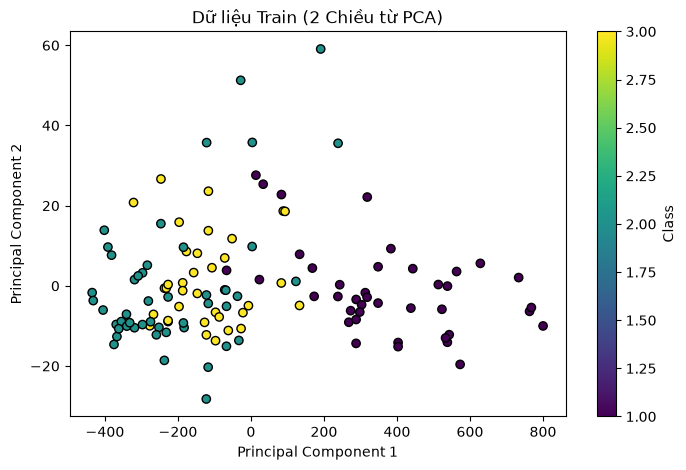

Độ chính xác (Accuracy) trên tập Test: 75.93%


In [13]:
cols = ["Class", "Alcohol", "Malic acid", "Ash", "Alcalinity of ash", "Magnesium",
        "Total phenols", "Flavanoids", "Nonflavanoid phenols", "Proanthocyanins",
        "Color intensity", "Hue", "OD280/OD315", "Proline"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
df = pd.read_csv(url,header= None, names= cols)

X = df.iloc[:,1:]
y = df.iloc[:,0]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=0)

#chuẩn hóa
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.fit_transform(X_test)

pca_full = PCA()
pca_full.fit(X_train)



#giảm chiều
pca = PCA(n_components= 2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', edgecolor='k')
plt.title('Dữ liệu Train (2 Chiều từ PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(scatter, label='Class')
plt.show()


model = LogisticRegression()
model.fit(X_train_pca,y_train)

#dự đoán
y_pred = model.predict(X_test_pca)
print(f"Độ chính xác (Accuracy) trên tập Test: {accuracy_score(y_test, y_pred) * 100:.2f}%")

In [15]:
#bài 2:
# Tạo danh sách Users (Sinh viên) và Items (Môn học)
users = ['SV01', 'SV02', 'SV03', 'SV04', 'SV05']
items = ['Toán rời rạc', 'Lập trình Python', 'Học máy', 'Hệ khuyến nghị']

# Tạo ma trận điểm (Sử dụng np.nan cho các ô cố ý để trống/chưa có điểm)
# Kích thước ma trận Y: 5 sinh viên x 4 môn học
R_true = np.array([
    [8.0, 7.5, np.nan, 9.0],
    [np.nan, 8.0, 6.5, 7.0],
    [5.0, np.nan, 7.0, 8.5],
    [7.0, 8.5, 8.0, np.nan],
    [np.nan, 9.0, np.nan, 6.0]
])

df_ratings = pd.DataFrame(R_true, index=users, columns=items)
print("Ma trận dữ liệu ban đầu (NaN là các môn chưa có điểm):")
print(df_ratings)

def matrix_factorization(R, K=2, epochs=5000, alpha=0.01, beta=0.02):
    N, M = R.shape 
    
    np.random.seed(42)
    X = np.random.rand(N, K)
    W = np.random.rand(M, K)
    
    non_nan_indices = np.argwhere(~np.isnan(R))
    
    for epoch in range(epochs):
        for i, j in non_nan_indices:
            e_ij = R[i, j] - np.dot(X[i, :], W[j, :].T)

            for k in range(K):
                x_ik_old = X[i, k]
                X[i, k] = X[i, k] + alpha * (2 * e_ij * W[j, k] - beta * X[i, k])
                W[j, k] = W[j, k] + alpha * (2 * e_ij * x_ik_old - beta * W[j, k])
                
    R_pred = np.dot(X, W.T)
    return X, W, R_pred

X, W, R_predicted = matrix_factorization(R_true, K=2)

df_predicted = pd.DataFrame(np.round(R_predicted, 2), index=users, columns=items)
print("Ma trận sau khi dự đoán (Đã điền các điểm còn thiếu):")
print(df_predicted)
print("\n")


# YÊU CẦU 3: ĐÁNH GIÁ MÔ HÌNH (RMSE)

print("="*40)
print("3. ĐÁNH GIÁ MÔ HÌNH")
print("="*40)

def calculate_rmse(R_true, R_pred):

    non_nan_indices = np.argwhere(~np.isnan(R_true))
    error_sq = 0
    count = len(non_nan_indices)
    
    for i, j in non_nan_indices:
        error = R_true[i, j] - R_pred[i, j]
        error_sq += error ** 2
    rmse = np.sqrt(error_sq / count)
    return rmse

final_rmse = calculate_rmse(R_true, R_predicted)
print(f"Giá trị Root Mean Squared Error (RMSE) cuối cùng: {final_rmse:.4f}")

Ma trận dữ liệu ban đầu (NaN là các môn chưa có điểm):
      Toán rời rạc  Lập trình Python  Học máy  Hệ khuyến nghị
SV01           8.0               7.5      NaN             9.0
SV02           NaN               8.0      6.5             7.0
SV03           5.0               NaN      7.0             8.5
SV04           7.0               8.5      8.0             NaN
SV05           NaN               9.0      NaN             6.0
Ma trận sau khi dự đoán (Đã điền các điểm còn thiếu):
      Toán rời rạc  Lập trình Python  Học máy  Hệ khuyến nghị
SV01          8.01              7.53     8.71            8.94
SV02          5.17              7.96     6.36            7.11
SV03          5.02             11.27     7.03            8.44
SV04          6.95              8.48     8.02            8.60
SV05          2.98              8.98     4.72            6.00


3. ĐÁNH GIÁ MÔ HÌNH
Giá trị Root Mean Squared Error (RMSE) cuối cùng: 0.0575


In [22]:
data = {
    'Môn học': ['Toán rời rạc', 'Lập trình Python', 'Học máy', 'Hệ khuyến nghị', 'Ngôn ngữ tự nhiên'],
    'Mô tả': [
        'Toán học cơ bản, logic, đồ thị và đại số',
        'Lập trình cơ bản với ngôn ngữ Python và thuật toán',
        'Các mô hình phân loại, hồi quy và mạng nơ-ron',
        'Thuật toán lọc cộng tác, phân rã ma trận và gợi ý', # Sinh viên chưa học
        'Xử lý văn bản, mô hình ngôn ngữ và trích xuất đặc trưng' # Sinh viên chưa học
    ],
    'Điểm': [8.0, 8.5, 9.0, np.nan, np.nan] 
}
df = pd.DataFrame(data)

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df['Mô tả']).toarray()

train = df['Điểm'].dropna().index
test = df[df['Điểm'].isna()].index

X_train = X_tfidf[train]
y_train = df.loc[train,'Điểm']
X_test = X_tfidf[test]

model = Ridge()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)
df.loc[test, 'Điểm dự đoán'] = np.round(y_pred, 2)
df.loc[train, 'Điểm dự đoán'] = np.round(model.predict(X_train), 2)

print("--- BÀI 1: CONTENT-BASED ---")
print(df[['Môn học', 'Điểm', 'Điểm dự đoán']])

--- BÀI 1: CONTENT-BASED ---
             Môn học  Điểm  Điểm dự đoán
0       Toán rời rạc   8.0          8.26
1   Lập trình Python   8.5          8.48
2            Học máy   9.0          8.75
3     Hệ khuyến nghị   NaN          8.52
4  Ngôn ngữ tự nhiên   NaN          8.54


In [23]:
df

,Môn học,Mô tả,Điểm,Điểm dự đoán
0,Toán rời rạc,"Toán học cơ bản, logic, đồ thị và đại số",8.0,8.26
1,Lập trình Python,Lập trình cơ bản với ngôn ngữ Python và thuật ...,8.5,8.48
2,Học máy,"Các mô hình phân loại, hồi quy và mạng nơ-ron",9.0,8.75
3,Hệ khuyến nghị,"Thuật toán lọc cộng tác, phân rã ma trận và gợi ý",NaN,8.52
4,Ngôn ngữ tự nhiên,"Xử lý văn bản, mô hình ngôn ngữ và trích xuất ...",NaN,8.54


In [24]:
from sklearn.metrics.pairwise import cosine_similarity
#user-user colab
# 1. Dữ liệu: 6 Sinh viên x 5 Môn học
ratings = np.array([
    [8.0, 7.0, np.nan, 9.0, 8.5], # Sinh viên A (Cần dự đoán Môn 3)
    [7.5, 6.5, 8.0, 8.5, 8.0],    # Sinh viên B (Học lực khá giống A)
    [9.0, 8.0, 7.0, 9.5, 9.0],    # Sinh viên C
    [4.0, 5.0, 6.0, 4.5, 5.5],    # Sinh viên D (Khác biệt hoàn toàn)
    [8.5, 7.5, 9.0, np.nan, 8.0], # Sinh viên E
    [6.0, 6.5, 5.0, 7.0, 6.5]     # Sinh viên F
])
df_ratings = pd.DataFrame(ratings, index=['A', 'B', 'C', 'D', 'E', 'F'],
                          columns=['Môn 1', 'Môn 2', 'Môn 3', 'Môn 4', 'Môn 5'])

target_user = 'A'
target_item = 'Môn 3'

# 2. Tính toán độ tương đồng (Cosine Similarity)
# Điền 0 vào các ô NaN để tính khoảng cách vector
df_filled = df_ratings.fillna(0)
sim_matrix = cosine_similarity(df_filled)
sim_df = pd.DataFrame(sim_matrix, index=df_ratings.index, columns=df_ratings.index)

# 3. Lấy Top-2 láng giềng của A (Loại bỏ chính A và chỉ chọn người đã học Môn 3)
sim_A = sim_df.loc[target_user].drop(target_user)
sim_A = sim_A[df_ratings[target_item].notna()] 
top_2 = sim_A.nlargest(2)

# 4. Dự đoán bằng Trung bình có trọng số (Weighted Average)
tu_so = sum(top_2[nb] * df_ratings.loc[nb, target_item] for nb in top_2.index)
mau_so = top_2.sum()
predicted_score = tu_so / mau_so

print("\n--- BÀI 2: USER-USER COLLABORATIVE FILTERING ---")
print(f"Top 2 sinh viên giống Sinh viên A nhất:\n{top_2}")
print(f"Điểm dự đoán cho Sinh viên A ở Môn 3: {predicted_score:.2f}")


--- BÀI 2: USER-USER COLLABORATIVE FILTERING ---
Top 2 sinh viên giống Sinh viên A nhất:
F    0.930505
C    0.929947
Name: A, dtype: float64
Điểm dự đoán cho Sinh viên A ở Môn 3: 6.00
